In [65]:
# Core
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('ggplot')

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

print("✔ Bibliothèques importées avec succès !")


✔ Bibliothèques importées avec succès !


In [67]:
# Chargement des données
train_data = pd.read_csv('train.csv')

# Nettoyage
train_data['Age'] = train_data['Age'].fillna(train_data['Age'].median())
train_data['Fare'] = train_data['Fare'].fillna(train_data['Fare'].median())
train_data['Embarked'] = train_data['Embarked'].fillna(train_data['Embarked'].mode()[0])

# Encodage des variables catégorielles
le = LabelEncoder()
train_data['Sex'] = le.fit_transform(train_data['Sex'])
train_data['Embarked'] = le.fit_transform(train_data['Embarked'])

print("✔ Données chargées et nettoyées !")


✔ Données chargées et nettoyées !


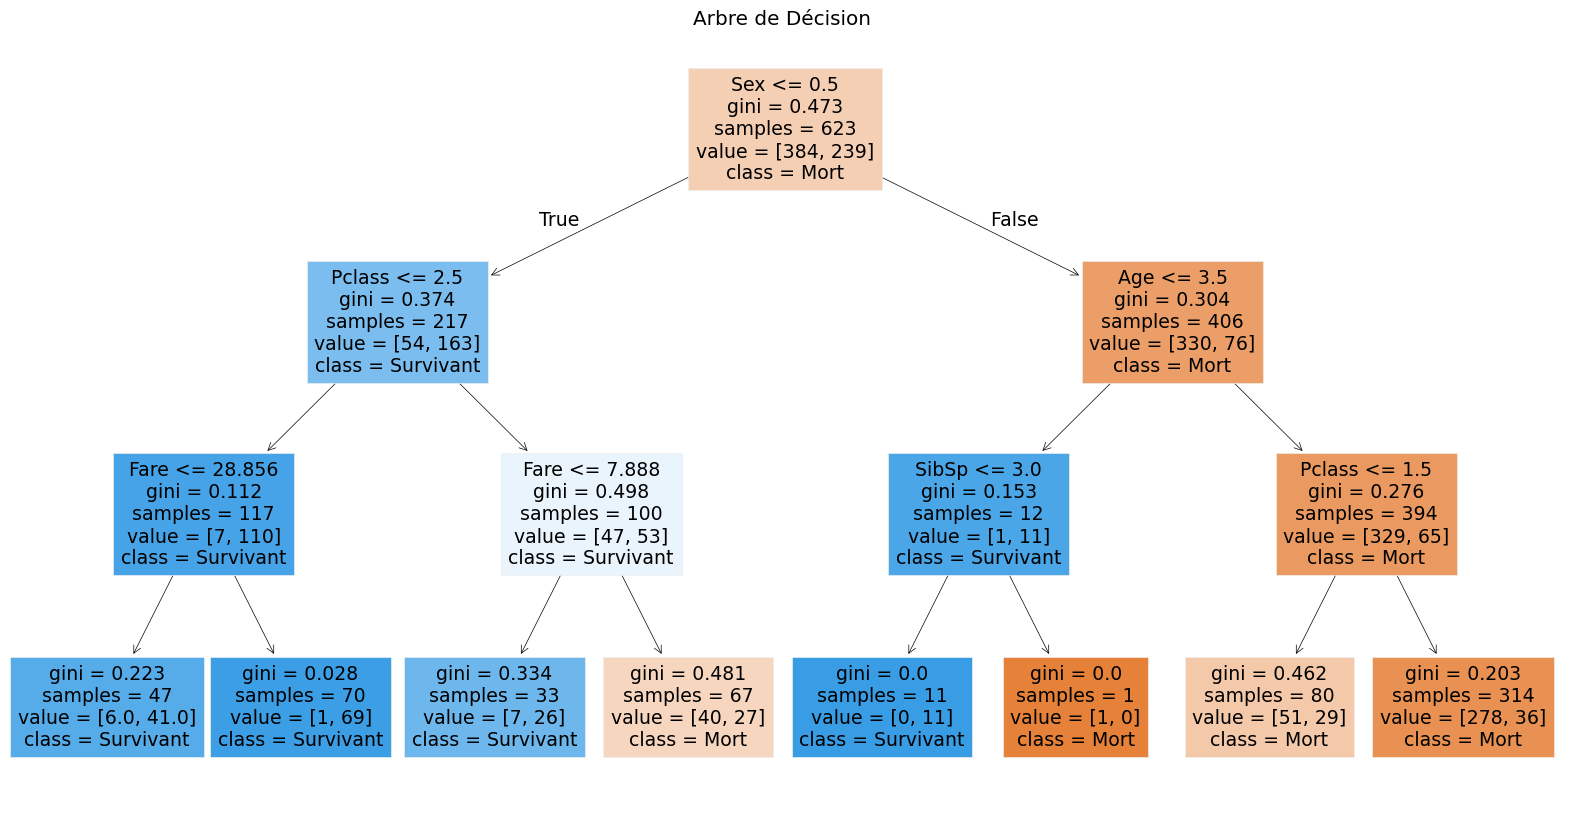

In [75]:
dt = DecisionTreeClassifier(max_depth=3, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
acc_dt = accuracy_score(y_test, y_pred_dt)

# Visualisation arbre
plt.figure(figsize=(20,10))
plot_tree(dt, feature_names=X.columns, class_names=['Mort', 'Survivant'], filled=True)
plt.title("Arbre de Décision ")
plt.show()



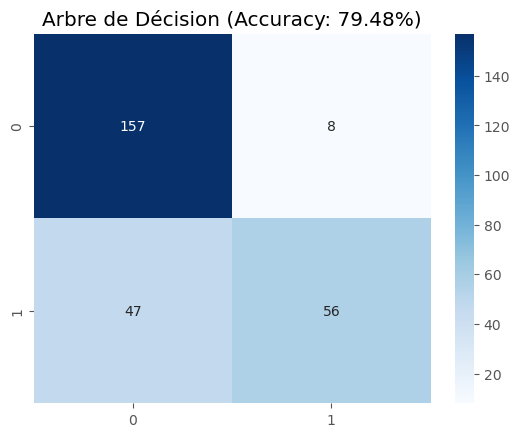

In [79]:
# Matrice de confusion
sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d', cmap='Blues')
plt.title(f"Arbre de Décision (Accuracy: {acc_dt:.2%})")
plt.show()


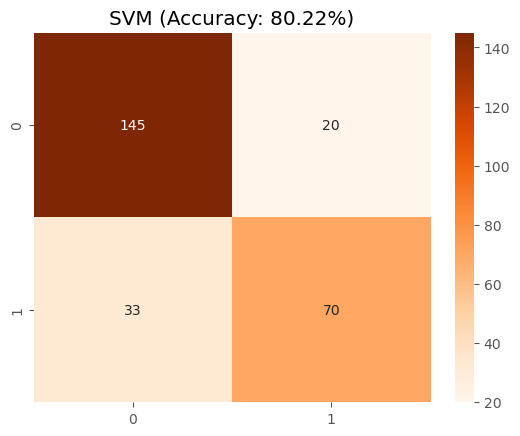

In [59]:
svm = SVC(kernel='rbf', random_state=42)
svm.fit(X_train_scaled, y_train)
y_pred_svm = svm.predict(X_test_scaled)
acc_svm = accuracy_score(y_test, y_pred_svm)

sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d', cmap='Oranges')
plt.title(f"SVM (Accuracy: {acc_svm:.2%})")
plt.show()


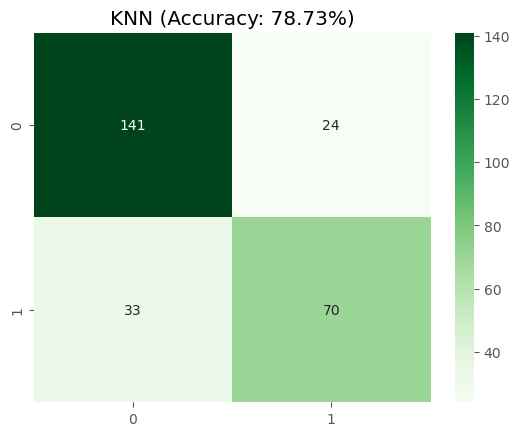

In [61]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)
acc_knn = accuracy_score(y_test, y_pred_knn)

sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='d', cmap='Greens')
plt.title(f"KNN (Accuracy: {acc_knn:.2%})")
plt.show()


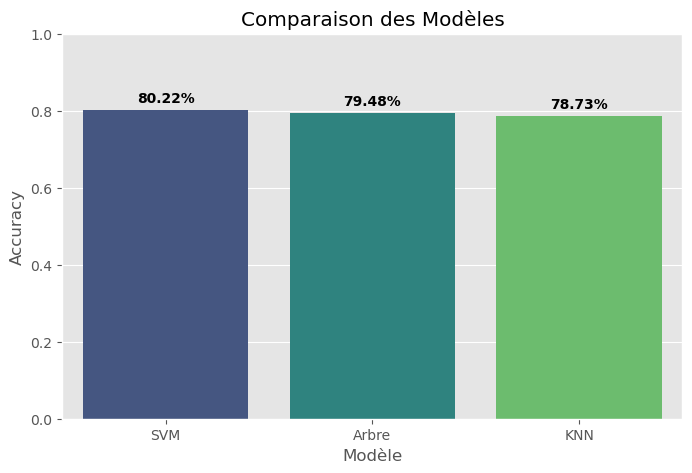

In [63]:
# DataFrame des résultats
results = pd.DataFrame({
    'Modèle': ['Arbre', 'SVM', 'KNN'],
    'Accuracy': [acc_dt, acc_svm, acc_knn]
}).sort_values('Accuracy', ascending=False)

# Visualisation
plt.figure(figsize=(8,5))
sns.barplot(x='Modèle', y='Accuracy', hue='Modèle', data=results, palette='viridis', legend=False)
plt.ylim(0, 1)
for i, v in enumerate(results['Accuracy']):
    plt.text(i, v+0.02, f"{v:.2%}", ha='center', fontweight='bold')
plt.title('Comparaison des Modèles')
plt.show()

